# Vision 과제: Beans 이미지 분류와 LoRA 추가 학습

ViT-Small을 사용해 콩잎을 **모무늬병 / 녹병 / 정상** 세 종류로 분류한다.
동일한 Test 전체에서 학습 전후 Accuracy와 개별 예측을 비교한다.
코드, 선택 이유, 전처리, 학습 설정 및 분석을 이 노트북 하나에 기록한다.

참고: 저장소의 `result_vision_classification.ipynb`.
예제의 실행 출력을 복사하지 않고, 직접 실행한 값으로 비교표와 결과 분석을 생성한다.


## 1. 과제 설정

- 태스크: Vision / 3-class image classification
- 모델: `WinKawaks/vit-small-patch16-224`
- 데이터: `AI-Lab-Makerere/beans`

| ID | 원래 레이블 | 의미 |
|---|---|---|
| 0 | angular_leaf_spot | 모무늬병 |
| 1 | bean_rust | 녹병 |
| 2 | healthy | 정상 |


In [1]:
# 모델·데이터와 학습 설정을 한곳에서 관리합니다.
TASK = "Vision"
MODEL_ID = "WinKawaks/vit-small-patch16-224"
DATASET_ID = "AI-Lab-Makerere/beans"
MODEL_REVISION = "main"       # 실행 시 정확한 Commit SHA로 고정해 기록
DATASET_REVISION = "main"
SEED = 42
OUTPUT_DIR = "./assignment_runs/vision"

LEARNING_RATE = 5e-4
NUM_EPOCHS = 3
BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 2


**선택 이유**

ViT-Small은 비교적 작은 사전학습 이미지 모델로, Attention에 LoRA를 넣어 학습하는
과정을 Colab GPU에서 실습하기 위해 선택했다. 이 체크포인트는 timm 가중치의
커뮤니티 변환본이며 모델 카드의 라이선스는 Apache 2.0이다.

Beans는 세 클래스의 잎 이미지와 공식 Train / Validation / Test 분할을 제공한다.
공식 데이터 규모는 각각 1,034 / 133 / 128개로, 전체 Test를 반복 평가하기에 적절하다.
데이터셋 카드의 라이선스는 MIT이다. 실제 크기와 클래스 분포는 실행 출력으로 확인한다.

[모델 카드](https://huggingface.co/WinKawaks/vit-small-patch16-224) ·
[데이터셋 카드](https://huggingface.co/datasets/AI-Lab-Makerere/beans)


## 2. 실행 환경

**Colab 실행 순서**

1. [Colab](https://colab.research.google.com/)에서 **파일 → 노트북 업로드**로 이 파일을 연다.
2. **런타임 → 런타임 유형 변경 → 하드웨어 가속기 → GPU(T4 등)**를 선택한다.
3. 바로 아래 **라이브러리 설치 셀 하나만 먼저 실행**한다.
4. 설치 완료 후 **런타임 → 세션 다시 시작**을 한 번 선택한다. 자동 재시작은 하지 않는다.
5. 위의 **1번 과제 설정 코드부터 설치 셀만 건너뛰고** 나머지 코드 셀을 순서대로 실행한다.
   처음부터 전체 실행으로 설치 셀을 반복 실행하지 않는다.

참고 예제의 주요 ML 라이브러리 버전을 고정한다. Colab의 기존 GPU용
`torch`·`torchvision` 조합은 유지하고, pandas는 설치된 호환 버전을 사용할 수 있다.
양자화를 사용하지 않으므로 import 충돌을 일으킬 수 있는 선택 패키지 `torchao`는 제거한다.
모델과 데이터는 공개 Hub에서 자동 다운로드하며 토큰 입력이나 Drive 연결은 요구하지 않는다.

설치 후 import 오류가 발생하면 먼저 세션을 다시 시작했는지 확인한다.
GPU 메모리가 부족하면 1번의 `BATCH_SIZE = 4`, `GRADIENT_ACCUMULATION_STEPS = 4`로
바꾸고 **과제 설정부터 설치 셀을 제외한 나머지를 다시 실행**한다.


In [2]:
# 설치 셀: 처음에 이 셀만 실행한 뒤 세션을 한 번 다시 시작하세요.
import sys
import subprocess
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

if sys.version_info < (3, 11):
    raise RuntimeError("Python 3.11 이상의 Colab 런타임을 사용하세요.")

requirements = [
    "transformers==5.23.0", "peft==0.21.3", "accelerate==1.16.0",
    "datasets==5.0.0", "huggingface-hub==1.32.0", "fsspec==2025.12.0",
    "pandas>=2.2,<4", "Pillow==12.3.0", "pyarrow==23.0.1",
]
constraints = Path("/tmp/vision-torch-constraints.txt")
constraints.write_text("\n".join(
    f"{package}=={version(package)}" for package in ("torch", "torchvision")
), encoding="utf-8")

def run_setup(command):
    result = subprocess.run(command, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True)
    print(result.stdout, flush=True)
    if result.returncode:
        raise RuntimeError("환경 설정 실패: 위 설치 로그의 오류를 확인하세요.")

run_setup([sys.executable, "-m", "pip", "install", "--disable-pip-version-check",
           "-c", str(constraints), *requirements])
try:
    version("torchao")
except PackageNotFoundError:
    pass
else:
    run_setup([sys.executable, "-m", "pip", "uninstall", "-y", "torchao"])
run_setup([sys.executable, "-c",
           "from transformers import pipeline, Trainer, AutoImageProcessor; "
           "from peft import LoraConfig, get_peft_model; "
           "from datasets import load_dataset; "
           "from PIL import Image; print('Import 검사 통과')"])
print("설치 완료. 런타임 메뉴에서 세션을 다시 시작하세요. 자동 재시작하지 않습니다.")


Import 검사 통과



설치 완료. 런타임 메뉴에서 세션을 다시 시작하세요. 자동 재시작하지 않습니다.


In [3]:
import os
import sys
import json
import importlib.metadata
from pathlib import Path
from datetime import datetime, timezone
from hashlib import sha256
from itertools import combinations

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
import numpy as np
import torch
import pandas as pd
from datasets import Dataset, DatasetDict, load_dataset
from huggingface_hub import HfApi
from transformers import (
    AutoConfig, AutoImageProcessor, AutoModelForImageClassification,
    Trainer, TrainingArguments, default_data_collator, pipeline, set_seed,
)
from peft import LoraConfig, PeftModel, get_peft_model
from IPython.display import display, Markdown

set_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("GPU가 없습니다. Colab 런타임 유형을 GPU로 변경하고 다시 실행하세요.")

PACKAGE_VERSIONS = {package: importlib.metadata.version(package) for package in (
    "torch", "torchvision", "transformers", "datasets", "peft", "accelerate",
    "huggingface-hub", "numpy", "pandas", "Pillow", "pyarrow", "fsspec",
)}
GPU_NAME = torch.cuda.get_device_name(0)
print("Python:", sys.version.split()[0])
print("GPU:", GPU_NAME)
display(pd.DataFrame(PACKAGE_VERSIONS.items(), columns=["library", "version"]))


Python: 3.13.16
GPU: Tesla T4


,library,version
0,torch,2.14.1+cu130
1,torchvision,0.29.1+cu130
2,transformers,5.23.0
3,datasets,5.0.0
4,peft,0.21.3
5,accelerate,1.16.0
6,huggingface-hub,1.32.0
7,numpy,2.4.6
8,pandas,2.2.3
9,Pillow,12.3.0


## 3. 데이터 로딩과 분할

Beans의 공식 Train / Validation / Test 분할을 유지한다. 제공된 `prepare_splits`는
분할이 없을 때만 무작위로 보충하며, 현재 데이터에는 재분할을 적용하지 않는다.
정답 열 이름은 `labels`이다. Test를 학습이나 하이퍼파라미터 선택에 사용하지 않는다.

실행 시 데이터셋 Revision을 Commit SHA로 고정하고, 분할 크기와 클래스 분포를 기록한다.
RGB 픽셀과 크기의 해시로 분할 내부 및 분할 사이의 **완전히 동일한 이미지**를 검사한다.
같은 잎의 다른 촬영이나 크롭까지 판별하는 검사는 아니며, 데이터에 식별 가능한
화자·개체 그룹이 있다면 개체 기준 분할이 추가로 필요하다.


In [4]:
# 공식 분할은 유지하고, 없는 분할만 보충합니다.
def prepare_splits(data, seed=SEED):
    splits = DatasetDict({"train": data}) if isinstance(data, Dataset) else DatasetDict(data)
    if "train" not in splits:
        raise ValueError("학습용 분할의 이름을 train으로 지정하세요.")
    if "test" not in splits:
        split = splits["train"].train_test_split(test_size=0.1, seed=seed)
        splits["train"], splits["test"] = split["train"], split["test"]
        validation_ratio = 1 / 9
    else:
        validation_ratio = 0.1
    if "validation" not in splits:
        split = splits["train"].train_test_split(test_size=validation_ratio, seed=seed)
        splits["train"], splits["validation"] = split["train"], split["test"]
    return DatasetDict({name: splits[name] for name in ("train", "validation", "test")})

dataset_revision = HfApi().dataset_info(DATASET_ID, revision=DATASET_REVISION).sha

def load_data():
    return load_dataset(DATASET_ID, revision=dataset_revision)

raw = prepare_splits(load_data())
labels = raw["train"].features["labels"].names
id2label = dict(enumerate(labels))
label2id = {label: i for i, label in id2label.items()}
assert len(labels) == 3
assert len(raw["test"]) >= 5
print("Dataset:", DATASET_ID, "Revision:", dataset_revision)
print(raw)
print("Label mapping:", id2label)
class_distribution = pd.DataFrame({
    name: pd.Series(data["labels"]).value_counts().reindex(range(len(labels)), fill_value=0)
    for name, data in raw.items()
}).rename(index=id2label)
display(class_distribution)

def image_fingerprint(image):
    rgb = image.convert("RGB")
    return sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()

fingerprints = {}
for name, data in raw.items():
    hashes = [image_fingerprint(row["image"]) for row in data]
    fingerprints[name] = set(hashes)
    print(name, "동일 픽셀 중복:", len(hashes) - len(set(hashes)))
for left, right in combinations(raw.keys(), 2):
    overlap = len(fingerprints[left] & fingerprints[right])
    print(f"{left} / {right} 동일 이미지: {overlap}개")
    assert overlap == 0, "분할 간 동일 이미지가 있습니다. 데이터 누출을 먼저 해결하세요."


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (6 outputs left out)

,train,validation,test
angular_leaf_spot,345,44,43
bean_rust,348,45,43
healthy,341,44,42


train 동일 픽셀 중복: 0


validation 동일 픽셀 중복: 0


test 동일 픽셀 중복: 0
train / validation 동일 이미지: 0개
train / test 동일 이미지: 0개
validation / test 동일 이미지: 0개


## 4. 모델과 전처리

사전학습 체크포인트의 이미지 특징 추출 부분을 불러오고, 기존 1,000-class 분류기를
Beans의 3-class 분류기로 교체한다. 새 분류기는 무작위 초기화되므로
`classifier.weight`·`classifier.bias` 크기 불일치 안내는 예상되는 출력이다.

이미지를 RGB로 변환하고 같은 Image processor로 224 × 224 크기 조정,
픽셀 스케일 변환 및 정규화를 적용한다. 학습과 평가에 무작위 증강은 사용하지 않는다.
`map` 결과는 모델 입력인 `pixel_values`와 정답 `labels`만 포함한다.


In [5]:
# 같은 모델 Revision으로 전처리기와 가중치를 불러옵니다.
model_revision = HfApi().model_info(MODEL_ID, revision=MODEL_REVISION).sha

def load_model_and_processor():
    set_seed(SEED)
    processor = AutoImageProcessor.from_pretrained(
        MODEL_ID, revision=model_revision, use_fast=False)
    config = AutoConfig.from_pretrained(MODEL_ID, revision=model_revision)
    config.num_labels = len(labels)
    config.id2label = id2label.copy()
    config.label2id = label2id.copy()
    model = AutoModelForImageClassification.from_pretrained(
        MODEL_ID, revision=model_revision, config=config,
        ignore_mismatched_sizes=True)
    return model, processor

model, processor = load_model_and_processor()

def preprocess(example):
    pixels = processor(images=example["image"].convert("RGB"),
                       return_tensors="np")["pixel_values"][0]
    return {"pixel_values": pixels, "labels": int(example["labels"])}

prepared = raw.map(preprocess, remove_columns=raw["train"].column_names,
                   writer_batch_size=16)
prepared.set_format("torch")
sample = prepared["train"][0]
assert tuple(sample["pixel_values"].shape) == (3, 224, 224)
assert sample["labels"].dtype == torch.int64
print("Base model:", MODEL_ID, "Revision:", model_revision)
print("Input:", sample["pixel_values"].shape, sample["pixel_values"].dtype)
print("Label mapping:", id2label)
print(processor)


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: WinKawaks/vit-small-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([3, 384])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Map:   0%|          | 0/1034 [00:00<?, ? examples/s]

Map:   0%|          | 0/133 [00:00<?, ? examples/s]

Map:   0%|          | 0/128 [00:00<?, ? examples/s]

Base model: WinKawaks/vit-small-patch16-224 Revision: 0c08c1829024fa177bd69b6dd09b05ad980854e1
Input: torch.Size([3, 224, 224]) torch.float32
Label mapping: {0: 'angular_leaf_spot', 1: 'bean_rust', 2: 'healthy'}
ViTImageProcessorPil {
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}



**전처리와 비교 해석**

정답과 예측은 같은 0 / 1 / 2 정수 레이블로 비교한다. Processor의 크기·평균·표준편차는
위 실행 출력에 기록한다. 추론에서도 같은 Processor와 RGB 변환을 사용한다.

학습 전 결과는 **사전학습된 특징 추출기 + 무작위로 초기화한 새 분류기**의 성능이다.
학습 후에는 **LoRA와 새 분류기를 함께 학습**했으므로 정확도 변화를 LoRA만의 효과로
해석할 수 없다. LoRA만의 기여를 분리하려면 분류기만 학습하는 대조 실험이 필요하다.


## 5. 학습 전 평가

`image-classification` pipeline을 사용하고 클래스 이름을 정수 ID로 변환한다.
Test 전체의 원래 순서를 유지하며 정답은 추론 입력에 넣지 않는다.
학습 전후 동일한 함수·데이터·Processor·Batch size로 평가한다.


In [6]:
# 전체 Test의 정답과 예측을 같은 정수 ID로 비교합니다.
def get_targets(test_data):
    return [int(label) for label in test_data["labels"]]

def predict_labels(current_model, processor, test_data):
    current_model.eval()
    # PEFT wrapper 대신 ViT를 pipeline에 전달한다. 삽입된 LoRA와 classifier는 유지된다.
    base = current_model.get_base_model() if isinstance(current_model, PeftModel) else current_model
    classifier = pipeline(
        "image-classification", model=base, image_processor=processor,
        device=0 if torch.cuda.is_available() else -1)
    images = [row["image"].convert("RGB") for row in test_data]
    with torch.inference_mode():
        outputs = classifier(images, batch_size=BATCH_SIZE, top_k=1)
    return [label2id[output[0]["label"]] for output in outputs]

def accuracy(targets, predictions):
    if len(targets) == 0 or len(targets) != len(predictions):
        raise ValueError("정답과 예측은 길이가 같고 비어 있지 않아야 합니다.")
    return sum(a == b for a, b in zip(targets, predictions)) / len(targets)

def evaluate_model(current_model, processor, test_data):
    targets = get_targets(test_data)
    predictions = predict_labels(current_model, processor, test_data)
    if len(targets) != len(test_data):
        raise ValueError("Test의 모든 샘플에 대해 정답과 예측을 반환하세요.")
    metrics = {"accuracy": accuracy(targets, predictions)}
    table = pd.DataFrame({"sample_id": range(len(targets)), "target": targets,
                          "prediction": predictions})
    return metrics, table

before_metrics, before = evaluate_model(model, processor, raw["test"])
print("학습 전 Test Accuracy:", f"{before_metrics['accuracy']:.2%}")
display(before.head(5))


학습 전 Test Accuracy: 31.25%


,sample_id,target,prediction
0,0,0,0
1,1,0,2
2,2,0,0
3,3,0,2
4,4,0,0


## 6. LoRA 적용

실제 모델의 모듈 이름을 확인해 Attention의 Query·Value 선형층에만 LoRA를 적용한다.
Transformers 버전에 따른 `query` / `value` 또는 `q_proj` / `v_proj` 이름을 확인한다.
새 분류기는 `modules_to_save=["classifier"]`로 학습·저장 대상에 포함한다.


In [7]:
# Attention의 Query·Value에 LoRA를 넣고 새 분류기도 학습합니다.
def make_lora_config(model):
    names = {name.rsplit(".", 1)[-1] for name, _ in model.named_modules()}
    if {"q_proj", "v_proj"} <= names:
        targets = ["q_proj", "v_proj"]
    elif {"query", "value"} <= names:
        targets = ["query", "value"]
    else:
        raise ValueError("model.named_modules()에서 Query/Value 이름을 확인하세요.")
    print("LoRA를 적용할 실제 모듈:")
    for name, module in model.named_modules():
        if name.rsplit(".", 1)[-1] in targets:
            print(" ", name)
    # Vision용 범용 PeftModel 사용: 텍스트용 task_type은 지정하지 않는다.
    return LoraConfig(r=8, lora_alpha=16, lora_dropout=0.1,
                      target_modules=targets, modules_to_save=["classifier"], bias="none")

lora_config = make_lora_config(model)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
trainable_names = [name for name, parameter in model.named_parameters() if parameter.requires_grad]
assert any("lora_" in name for name in trainable_names)
assert any("classifier" in name for name in trainable_names)
assert all("lora_" in name or "classifier" in name for name in trainable_names)
trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_count = sum(p.numel() for p in model.parameters())


LoRA를 적용할 실제 모듈:
  vit.layers.0.attention.q_proj
  vit.layers.0.attention.v_proj
  vit.layers.1.attention.q_proj
  vit.layers.1.attention.v_proj
  vit.layers.2.attention.q_proj
  vit.layers.2.attention.v_proj
  vit.layers.3.attention.q_proj
  vit.layers.3.attention.v_proj
  vit.layers.4.attention.q_proj
  vit.layers.4.attention.v_proj
  vit.layers.5.attention.q_proj
  vit.layers.5.attention.v_proj
  vit.layers.6.attention.q_proj
  vit.layers.6.attention.v_proj
  vit.layers.7.attention.q_proj
  vit.layers.7.attention.v_proj
  vit.layers.8.attention.q_proj
  vit.layers.8.attention.v_proj
  vit.layers.9.attention.q_proj
  vit.layers.9.attention.v_proj
  vit.layers.10.attention.q_proj
  vit.layers.10.attention.v_proj
  vit.layers.11.attention.q_proj
  vit.layers.11.attention.v_proj
trainable params: 148,611 || all params: 21,815,430 || trainable%: 0.6812


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


**LoRA 설정 이유**

- `r=8`, `lora_alpha=16`: 소규모 데이터 실습의 기본 설정으로 사용한다.
- `lora_dropout=0.1`: LoRA 경로에 Dropout을 적용한다.
- Query·Value만 선택해 학습할 파라미터 수를 줄인다.
- `bias="none"`: 기존 선형층의 bias는 추가 학습하지 않는다.
- `modules_to_save=["classifier"]`: 무작위 초기화한 분류기를 함께 학습하고 저장한다.

나머지 기존 가중치는 고정한다. 위 출력과 검사로 실제 학습 대상을 확인한다.
이 설정의 최적성을 주장하지 않으며, Test 점수로 설정을 선택하지 않는다.
구현은 [PEFT의 이미지 분류 LoRA 가이드](https://huggingface.co/docs/peft/main/en/task_guides/image_classification_lora)를 참고했다.


## 7. 학습

학습률 `5e-4`, `3 Epoch`, Batch size `8`, Gradient accumulation `2`로 학습한다.
GPU 한 개의 유효 Batch size는 16이다. 분류 Cross Entropy Loss를 사용하고
고정 크기의 이미지 Tensor는 `default_data_collator`로 묶는다.

매 Epoch Validation Loss·Accuracy를 기록한다. 이 실습은 사전에 정한 마지막 Epoch
모델을 평가하며 최적 체크포인트를 선택하지 않는다. Test는 Trainer에 전달하지 않는다.
T4에서 사용할 수 있는 FP16을 적용하고 외부 실험 추적·업로드는 설정하지 않는다.


In [8]:
# Train으로 학습하고 Validation으로 진행 상황을 확인합니다.
def compute_metrics(result):
    logits = result.predictions[0] if isinstance(result.predictions, tuple) else result.predictions
    return {"accuracy": accuracy(result.label_ids.tolist(), np.asarray(logits).argmax(-1).tolist())}

def make_trainer(model, processor, train_data, validation_data):
    args = TrainingArguments(
        output_dir=OUTPUT_DIR, learning_rate=LEARNING_RATE, num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        eval_strategy="epoch", save_strategy="no", optim="adamw_torch",
        fp16=torch.cuda.is_available(), bf16=False,
        remove_unused_columns=False, label_names=["labels"],
        dataloader_num_workers=0, dataloader_pin_memory=torch.cuda.is_available(),
        report_to="none", seed=SEED, data_seed=SEED, logging_steps=20)
    return Trainer(model=model, args=args, train_dataset=train_data,
                   eval_dataset=validation_data, processing_class=processor,
                   data_collator=default_data_collator, compute_metrics=compute_metrics)

trainer = make_trainer(model, processor, prepared["train"], prepared["validation"])
train_result = trainer.train()
print("학습 결과:", train_result.metrics)
validation_history = pd.DataFrame([
    {key: row[key] for key in ("epoch", "eval_loss", "eval_accuracy") if key in row}
    for row in trainer.state.log_history if "eval_loss" in row
])
display(validation_history)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.189631,0.093646,0.962406
2,0.094306,0.072428,0.962406
3,0.033915,0.047974,0.977444


학습 결과: {'train_runtime': 199.1036, 'train_samples_per_second': 15.58, 'train_steps_per_second': 0.979, 'total_flos': 6.111870067150848e+16, 'train_loss': 0.1924082412933692, 'epoch': 3.0}


,epoch,eval_loss,eval_accuracy
0,1.0,0.093646,0.962406
1,2.0,0.072428,0.962406
2,3.0,0.047974,0.977444


## 8. 학습 후 평가

학습 전과 같은 Test 전체를 같은 순서로 평가한다. 최소 5개의 예측과 입력 이미지를
비교하고, 전체 예측표·클래스별 Recall·혼동행렬·실제 오분류 사례를 확인한다.
성능이 개선되지 않거나 일부 샘플이 나빠져도 결과를 그대로 기록한다.


,before,after
accuracy,0.3125,0.953125


전체 Test 예측 비교:


,sample_id,target,before,after,target_name,before_name,after_name
0,0,0,0,0,angular_leaf_spot,angular_leaf_spot,angular_leaf_spot
1,1,0,2,0,angular_leaf_spot,healthy,angular_leaf_spot
2,2,0,0,0,angular_leaf_spot,angular_leaf_spot,angular_leaf_spot
3,3,0,2,0,angular_leaf_spot,healthy,angular_leaf_spot
4,4,0,0,0,angular_leaf_spot,angular_leaf_spot,angular_leaf_spot
...,...,...,...,...,...,...,...
123,123,2,0,2,healthy,angular_leaf_spot,healthy
124,124,2,0,2,healthy,angular_leaf_spot,healthy
125,125,2,0,2,healthy,angular_leaf_spot,healthy
126,126,2,0,2,healthy,angular_leaf_spot,healthy


,sample_id,target_name,before_name,after_name
0,0,angular_leaf_spot,angular_leaf_spot,angular_leaf_spot
43,43,bean_rust,angular_leaf_spot,bean_rust
86,86,healthy,angular_leaf_spot,healthy
1,1,angular_leaf_spot,healthy,angular_leaf_spot
2,2,angular_leaf_spot,angular_leaf_spot,angular_leaf_spot


Test #0: 정답=angular_leaf_spot, 전=angular_leaf_spot, 후=angular_leaf_spot


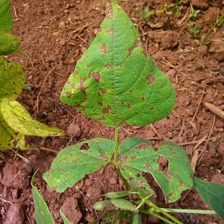

Test #43: 정답=bean_rust, 전=angular_leaf_spot, 후=bean_rust


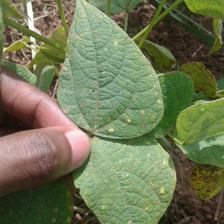

Test #86: 정답=healthy, 전=angular_leaf_spot, 후=healthy


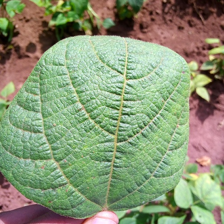

Test #1: 정답=angular_leaf_spot, 전=healthy, 후=angular_leaf_spot


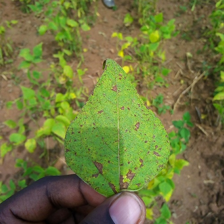

Test #2: 정답=angular_leaf_spot, 전=angular_leaf_spot, 후=angular_leaf_spot


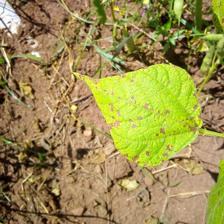

클래스별 결과 (Recall = 실제 해당 클래스 중 맞힌 비율):


,count,correct,recall
target,,,
angular_leaf_spot,43,40,0.930233
bean_rust,43,41,0.953488
healthy,42,41,0.976190


혼동행렬: 행=정답, 열=학습 후 예측


after,angular_leaf_spot,bean_rust,healthy
target,,,
angular_leaf_spot,40,3,0
bean_rust,2,41,0
healthy,0,1,41


학습 후 오분류 사례 (최대 3개):
Test #6: 정답=angular_leaf_spot, 예측=bean_rust


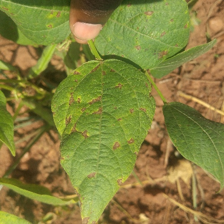

Test #30: 정답=angular_leaf_spot, 예측=bean_rust


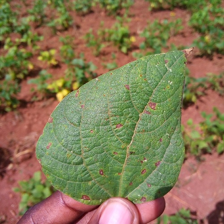

Test #37: 정답=angular_leaf_spot, 예측=bean_rust


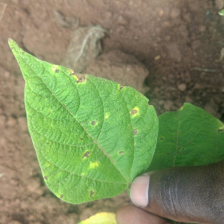

In [9]:
# 학습 전후 동일한 Test를 평가하고 개별 예측을 비교합니다.
after_metrics, after = evaluate_model(model, processor, raw["test"])
assert len(before) >= 5 and len(after) >= 5
assert before["sample_id"].is_unique and after["sample_id"].is_unique
assert before[["sample_id", "target"]].reset_index(drop=True).equals(
    after[["sample_id", "target"]].reset_index(drop=True)
), "학습 전후 같은 샘플·순서·정답을 사용하세요."
comparison = before.rename(columns={"prediction": "before"}).merge(
    after[["sample_id", "prediction"]].rename(columns={"prediction": "after"}),
    on="sample_id", validate="one_to_one")
for column in ("target", "before", "after"):
    comparison[f"{column}_name"] = comparison[column].map(id2label)
before_correct = comparison["before"] == comparison["target"]
after_correct = comparison["after"] == comparison["target"]
delta_pp = (after_metrics["accuracy"] - before_metrics["accuracy"]) * 100
improved_count = int((~before_correct & after_correct).sum())
regressed_count = int((before_correct & ~after_correct).sum())

display(pd.DataFrame({"before": before_metrics, "after": after_metrics}))
print("전체 Test 예측 비교:")
display(comparison)
# 클래스별 한 개씩 먼저 고르고 나머지를 채워 최소 5개를 명시적으로 출력한다.
preview = pd.concat([comparison.groupby("target", sort=True).head(1), comparison])
preview = preview.drop_duplicates("sample_id").head(5)
display(preview[["sample_id", "target_name", "before_name", "after_name"]])
for row in preview.itertuples(index=False):
    print(f"Test #{row.sample_id}: 정답={row.target_name}, 전={row.before_name}, 후={row.after_name}")
    display(raw["test"][row.sample_id]["image"].convert("RGB").resize((224, 224)))

class_results = comparison.assign(correct=after_correct).groupby("target")["correct"].agg(
    count="count", correct="sum", recall="mean").reindex(range(len(labels)))
class_results = class_results.rename(index=id2label)
print("클래스별 결과 (Recall = 실제 해당 클래스 중 맞힌 비율):")
display(class_results)
confusion = pd.crosstab(comparison["target"], comparison["after"]).reindex(
    index=range(len(labels)), columns=range(len(labels)), fill_value=0)
confusion = confusion.rename(index=id2label, columns=id2label)
print("혼동행렬: 행=정답, 열=학습 후 예측")
display(confusion)
failures = comparison.loc[~after_correct]
if failures.empty:
    print("이번 Test에서 오분류 없음. 다른 환경에서의 일반화를 보장하지는 않습니다.")
else:
    print("학습 후 오분류 사례 (최대 3개):")
    for row in failures.head(3).itertuples(index=False):
        print(f"Test #{row.sample_id}: 정답={row.target_name}, 예측={row.after_name}")
        display(raw["test"][row.sample_id]["image"].convert("RGB").resize((224, 224)))


## 9. 저장과 분석

Adapter와 함께 추가 학습한 분류기, Processor, 모델 설정을 저장한다.
저장 파일에 LoRA와 분류기 가중치가 모두 포함되는지 확인한다.
기본 모델 가중치와 데이터셋은 포함하지 않으며 재사용 시 아래에 기록된 모델 Revision이 필요하다.

환경·학습 설정과 실제 결과도 JSON으로 보관한다. 이 폴더는 Colab 런타임의 임시 공간이므로
재사용할 때는 세션이 끝나기 전에 내려받거나 Drive에 보관한다.
**과제 제출 대상은 실행 출력과 아래 결과 분석을 포함한 `.ipynb` 하나이다.**


In [10]:
# LoRA와 분류기를 저장하고 실제 저장된 가중치를 확인합니다.
from safetensors import safe_open

adapter_dir = Path(OUTPUT_DIR) / "adapter"
model.save_pretrained(adapter_dir, safe_serialization=True)
processor.save_pretrained(adapter_dir)
model.config.save_pretrained(adapter_dir)
with safe_open(str(adapter_dir / "adapter_model.safetensors"), framework="pt", device="cpu") as handle:
    saved_keys = list(handle.keys())
assert any("lora_" in key for key in saved_keys), "LoRA 가중치 저장을 확인하세요."
assert any("classifier" in key for key in saved_keys), "분류기 가중치 저장을 확인하세요."

run_metadata = {
    "run_time_utc": datetime.now(timezone.utc).isoformat(),
    "task": TASK, "base_model": MODEL_ID, "model_revision": model_revision,
    "dataset": DATASET_ID, "dataset_revision": dataset_revision,
    "split_sizes": {name: len(data) for name, data in raw.items()},
    "labels": id2label, "seed": SEED, "gpu": GPU_NAME,
    "python": sys.version.split()[0], "libraries": PACKAGE_VERSIONS,
    "training": {"learning_rate": LEARNING_RATE, "epochs": NUM_EPOCHS,
                 "batch_size": BATCH_SIZE, "gradient_accumulation": GRADIENT_ACCUMULATION_STEPS,
                 "fp16": trainer.args.fp16, "optimizer": "adamw_torch",
                 "model_selection": "final epoch; test not used for selection"},
    "lora": {"r": lora_config.r, "alpha": lora_config.lora_alpha,
             "dropout": lora_config.lora_dropout,
             "target_modules": sorted(lora_config.target_modules),
             "modules_to_save": sorted(lora_config.modules_to_save)},
    "trainable_parameters": trainable_count, "total_parameters": total_count,
    "before": before_metrics, "after": after_metrics, "delta_percentage_points": delta_pp,
    "train_metrics": train_result.metrics,
    "validation_history": validation_history.to_dict(orient="records"),
    "adapter_dir": str(adapter_dir.resolve()),
}
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
(Path(OUTPUT_DIR) / "run_metadata.json").write_text(
    json.dumps(run_metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print("Base model:", MODEL_ID, "Revision:", model_revision)
print("Dataset Revision:", dataset_revision)
print("Adapter·분류기·Processor·모델 설정:", adapter_dir.resolve())
print("LoRA 및 classifier 가중치 저장 확인 완료")


Base model: WinKawaks/vit-small-patch16-224 Revision: 0c08c1829024fa177bd69b6dd09b05ad980854e1
Dataset Revision: 27aa014ce09b193e1a6f58112d4a66e0eddb69c5
Adapter·분류기·Processor·모델 설정: /content/assignment_runs/vision/adapter
LoRA 및 classifier 가중치 저장 확인 완료


### 결과 분석

다음 셀은 위에서 직접 측정한 값으로 분석을 출력한다. 실행하지 않은 수치나 예제의 정확도를
본인의 결과로 기입하지 않는다. 전후 성능 변화에는 LoRA와 새 분류기의 학습 효과가 함께 포함된다.
클래스별 Recall과 실패 이미지는 직전 출력에서 확인할 수 있다.


In [11]:
# 이 실행에서 측정한 값으로 결과 분석을 작성합니다.
n_test = len(comparison)
runtime_seconds = float(train_result.metrics["train_runtime"])
split_summary = " / ".join(f"{name} {len(raw[name]):,}개" for name in ("train", "validation", "test"))
if failures.empty:
    failure_summary = "이번 Test에서는 오분류가 관찰되지 않았다. 다른 촬영 환경에서도 오류가 없다는 의미는 아니다."
else:
    failure_summary = "실제로 관찰된 오분류는 다음과 같다.\n" + "\n".join(
        f"- Test #{row.sample_id}: 정답 `{row.target_name}`, 학습 후 예측 `{row.after_name}`"
        for row in failures.head(3).itertuples(index=False))

validation_summary = " / ".join(
    f"Epoch {row['epoch']:.0f}: Loss {row['eval_loss']:.4f}, Accuracy {row['eval_accuracy']:.2%}"
    for row in validation_history.to_dict(orient="records"))
if delta_pp > 0:
    change_summary = f"정확도가 {delta_pp:.2f}%p 상승했다."
elif delta_pp < 0:
    change_summary = f"정확도가 {abs(delta_pp):.2f}%p 하락했다."
else:
    change_summary = "정확도는 같았다."

analysis_text = f"""### 실제 실행 결과 분석

**모델과 데이터**

- Base model: `{MODEL_ID}`, Revision: `{model_revision}`
- Dataset: `{DATASET_ID}`, Revision: `{dataset_revision}`
- 공식 분할 유지: {split_summary}. 평가 지표는 Accuracy이다.
- Adapter·분류기·Processor·모델 설정 저장 위치: `{adapter_dir.resolve()}`

**학습 전후 변화**

동일한 Test {n_test}개에서 Accuracy는 **{before_metrics['accuracy']:.2%} → {after_metrics['accuracy']:.2%}**였다.
{change_summary} 정답 수는 {int(before_correct.sum())}/{n_test}에서 {int(after_correct.sum())}/{n_test}로 변했다.
오답에서 정답으로 바뀐 샘플은 {improved_count}개, 정답에서 오답으로 바뀐 샘플은 {regressed_count}개였다.
전체 지표와 개별 예측 변화가 같지는 않을 수 있으므로 위의 최소 5개 비교표와 입력 이미지도 함께 확인했다.

**학습 설정과 Validation**

학습률 {LEARNING_RATE}, {NUM_EPOCHS} Epoch, Batch size {BATCH_SIZE}, Gradient accumulation
{GRADIENT_ACCUMULATION_STEPS}로 학습했다. 단일 GPU 유효 Batch size는
{BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS}이다. 최종 Epoch 모델을 평가했고 Test로 설정을 고르지 않았다.

{validation_summary}

Trainer가 기록한 학습 구간은 {runtime_seconds:.2f}초 ({runtime_seconds / 60:.2f}분)였다.
데이터·모델 다운로드, 전처리, 학습 전후 Test 평가와 저장 시간은 포함하지 않는다.
전체 {total_count:,}개 중 {trainable_count:,}개 ({100 * trainable_count / total_count:.4f}%)를 학습했다.
이 수에는 LoRA와 새 분류기가 포함된다.

**실패 사례와 해석**

{failure_summary}

혼동행렬과 클래스별 Recall은 위에 출력했다. 클래스별 표본 수가 작으며,
잎의 병변 모양·조명·배경 중 무엇이 오류의 원인인지는 이 결과만으로 확정하지 않는다.

**결과 해석의 조건과 한계**

학습 전 분류기는 무작위 초기화 상태였다. 따라서 개선이 있어도 이를 LoRA만의 효과로 볼 수 없다.
분류기만 학습하는 대조 실험과 전체 파인튜닝 실험을 하지 않아 LoRA만의 성능 기여나
속도·메모리 절감률은 측정하지 않았다. 동일 RGB 픽셀 중복 검사는 유사 이미지나 같은 잎의
다른 촬영까지 배제하지 못한다. 단일 Seed와 작은 Test 결과로 다른 촬영 환경의 성능을 보장하지 않는다.

**개선 방향**

Validation에서 학습률·LoRA Rank·학습 횟수를 비교하고, 학습 데이터에만 증강을 적용하는 실험을 할 수 있다.
여러 Seed와 별도 촬영 데이터로 안정성을 확인하고, 분류기만 학습하는 대조 실험으로 LoRA의 기여를 비교할 수 있다.
Test는 최종 평가용으로 유지한다.
"""
display(Markdown(analysis_text))
(Path(OUTPUT_DIR) / "analysis.md").write_text(analysis_text, encoding="utf-8")
print("실행 완료. 출력이 포함된 노트북을 .ipynb로 다운로드해 제출하세요.")


### 실제 실행 결과 분석

**모델과 데이터**

- Base model: `WinKawaks/vit-small-patch16-224`, Revision: `0c08c1829024fa177bd69b6dd09b05ad980854e1`
- Dataset: `AI-Lab-Makerere/beans`, Revision: `27aa014ce09b193e1a6f58112d4a66e0eddb69c5`
- 공식 분할 유지: train 1,034개 / validation 133개 / test 128개. 평가 지표는 Accuracy이다.
- Adapter·분류기·Processor·모델 설정 저장 위치: `/content/assignment_runs/vision/adapter`

**학습 전후 변화**

동일한 Test 128개에서 Accuracy는 **31.25% → 95.31%**였다.
정확도가 64.06%p 상승했다. 정답 수는 40/128에서 122/128로 변했다.
오답에서 정답으로 바뀐 샘플은 85개, 정답에서 오답으로 바뀐 샘플은 3개였다.
전체 지표와 개별 예측 변화가 같지는 않을 수 있으므로 위의 최소 5개 비교표와 입력 이미지도 함께 확인했다.

**학습 설정과 Validation**

학습률 0.0005, 3 Epoch, Batch size 8, Gradient accumulation
2로 학습했다. 단일 GPU 유효 Batch size는
16이다. 최종 Epoch 모델을 평가했고 Test로 설정을 고르지 않았다.

Epoch 1: Loss 0.0936, Accuracy 96.24% / Epoch 2: Loss 0.0724, Accuracy 96.24% / Epoch 3: Loss 0.0480, Accuracy 97.74%

Trainer가 기록한 학습 구간은 199.10초 (3.32분)였다.
데이터·모델 다운로드, 전처리, 학습 전후 Test 평가와 저장 시간은 포함하지 않는다.
전체 21,815,430개 중 148,611개 (0.6812%)를 학습했다.
이 수에는 LoRA와 새 분류기가 포함된다.

**실패 사례와 해석**

실제로 관찰된 오분류는 다음과 같다.
- Test #6: 정답 `angular_leaf_spot`, 학습 후 예측 `bean_rust`
- Test #30: 정답 `angular_leaf_spot`, 학습 후 예측 `bean_rust`
- Test #37: 정답 `angular_leaf_spot`, 학습 후 예측 `bean_rust`

혼동행렬과 클래스별 Recall은 위에 출력했다. 클래스별 표본 수가 작으며,
잎의 병변 모양·조명·배경 중 무엇이 오류의 원인인지는 이 결과만으로 확정하지 않는다.

**결과 해석의 조건과 한계**

학습 전 분류기는 무작위 초기화 상태였다. 따라서 개선이 있어도 이를 LoRA만의 효과로 볼 수 없다.
분류기만 학습하는 대조 실험과 전체 파인튜닝 실험을 하지 않아 LoRA만의 성능 기여나
속도·메모리 절감률은 측정하지 않았다. 동일 RGB 픽셀 중복 검사는 유사 이미지나 같은 잎의
다른 촬영까지 배제하지 못한다. 단일 Seed와 작은 Test 결과로 다른 촬영 환경의 성능을 보장하지 않는다.

**개선 방향**

Validation에서 학습률·LoRA Rank·학습 횟수를 비교하고, 학습 데이터에만 증강을 적용하는 실험을 할 수 있다.
여러 Seed와 별도 촬영 데이터로 안정성을 확인하고, 분류기만 학습하는 대조 실험으로 LoRA의 기여를 비교할 수 있다.
Test는 최종 평가용으로 유지한다.


실행 완료. 출력이 포함된 노트북을 .ipynb로 다운로드해 제출하세요.


## 10. Colab 저장 및 제출

1. 마지막 코드 셀까지 오류 없이 실행됐는지 확인한다.
2. 8번에 학습 전후 Accuracy, 최소 5개 예측 비교와 이미지가 표시되는지 확인한다.
3. 9번에 저장 확인 메시지와 **실제 실행 결과 분석**이 표시되는지 확인한다.
4. **파일 → 다운로드 → .ipynb 다운로드**를 선택한다.
5. 받은 파일을 `week9_vision_본인이름.ipynb`처럼 알아보기 쉽게 이름 지어 제출한다.
   다운로드한 파일을 다시 열어 표·이미지·분석 출력이 남아 있는지 확인한다.

노트북 설정에 **저장 시 코드 셀 출력 제외** 항목이 켜져 있다면 해제한다.
출력을 지우거나 `.py`로 변환하지 않는다. 제출할 파일은 **실행 출력과 분석이 포함된
노트북 하나**이며 Adapter·JSON·ZIP 등은 별도 제출하지 않는다.

모델 재사용을 위해 Adapter를 보관하려면 Colab 왼쪽 파일 패널에서
`/content/assignment_runs/vision/adapter`의 파일들을 내려받거나 Drive에 복사한다.
이 보관 작업은 과제 제출과는 별개이다.

이 노트북은 저장소의 Vision 예제와
[Transformers 이미지 분류 가이드](https://huggingface.co/docs/transformers/en/tasks/image_classification),
[PEFT 이미지 분류 LoRA 가이드](https://huggingface.co/docs/peft/main/en/task_guides/image_classification_lora)를 참고해 작성했다.
